# Overview

1. Project Instructions & Prerequisites
2. Learning Objectives
3. Data Preparation
4. Create Categorical Features with TF Feature Columns
5. Create Continuous/Numerical Features with TF Feature Columns
6. Build Deep Learning Regression Model with Sequential API and TF Probability Layers
7. Evaluating Potential Model Biases with Aequitas Toolkit


#  1. Project Instructions & Prerequisites

## Project Instructions

**Context**: EHR data is becoming a key source of real-world evidence (RWE) for the pharmaceutical industry and regulators to [make decisions on clinical trials](https://www.fda.gov/news-events/speeches-fda-officials/breaking-down-barriers-between-clinical-trials-and-clinical-care-incorporating-real-world-evidence). You are a data scientist for an exciting unicorn healthcare startup that has created a groundbreaking diabetes drug that is ready for clinical trial testing. It is a very unique and sensitive drug that requires administering the drug over at least 5-7 days of time in the hospital with frequent monitoring/testing and patient medication adherence training with a mobile application. You have been provided a patient dataset from a client partner and are tasked with building a predictive model that can identify which type of patients the company should focus their efforts testing this drug on. Target patients are people that are likely to be in the hospital for this duration of time and will not incur significant additional costs for administering this drug to the patient and monitoring.  

In order to achieve your goal you must build a regression model that can predict the estimated hospitalization time for a patient and use this to select/filter patients for your study.


**Expected Hospitalization Time Regression Model:** Utilizing a synthetic dataset(denormalized at the line level augmentation) built off of the UCI Diabetes readmission dataset, students will build a regression model that predicts the expected days of hospitalization time and then convert this to a binary prediction of whether to include or exclude that patient from the clinical trial.

This project will demonstrate the importance of building the right data representation at the encounter level, with appropriate filtering and preprocessing/feature engineering of key medical code sets. This project will also require students to analyze and interpret their model for biases across key demographic groups. 

### Dataset

Due to healthcare PHI regulations (HIPAA, HITECH), there are limited number of publicly available datasets and some datasets require training and approval. So, for the purpose of this exercise, we are using a dataset from UC Irvine(https://archive.ics.uci.edu/ml/datasets/Diabetes+130-US+hospitals+for+years+1999-2008) that has been modified for this course. Please note that it is limited in its representation of some key features such as diagnosis codes which are usually an unordered list in 835s/837s (the HL7 standard interchange formats used for claims and remits).

**Data Schema**
The dataset reference information can be https://github.com/udacity/nd320-c1-emr-data-starter/blob/master/project/data_schema_references/
. There are two CSVs that provide more details on the fields and some of the mapped values.

## Environment Setup

For step by step instructions on creating your environment, please go to https://github.com/udacity/nd320-c1-emr-data-starter/blob/master/project/README.md.

# 2.  Learning Objectives

By the end of the project, I am expected to be able to 
   - Use the Tensorflow Dataset API to scalably extract, transform, and load datasets and build datasets aggregated at the line, encounter, and patient data levels(longitudinal)
   - Analyze EHR datasets to check for common issues (data leakage, statistical properties, missing values, high cardinality) by performing exploratory data analysis.
   - Create categorical features from Key Industry Code Sets (ICD, CPT, NDC) and reduce dimensionality for high cardinality features by using embeddings 
   - Create derived features(bucketing, cross-features, embeddings) utilizing Tensorflow feature columns on both continuous and categorical input features
   - SWBAT use the Tensorflow Probability library to train a model that provides uncertainty range predictions that allow for risk adjustment/prioritization and triaging of predictions
   - Analyze and determine biases for a model for key demographic groups by evaluating performance metrics across groups by using the Aequitas framework 


# 3. Data Preparation

In [1]:
# from __future__ import absolute_import, division, print_function, unicode_literals
import os
import numpy as np

import tensorflow as tf
from tensorflow.keras import layers
import tensorflow_probability as tfp
import matplotlib.pyplot as plt
import pandas as pd
import aequitas as ae
# Put all of the helper functions in utils
from utils import build_vocab_files, show_group_stats_viz, aggregate_dataset, preprocess_df, df_to_dataset, posterior_mean_field, prior_trainable
pd.set_option('display.max_columns', 500)
# this allows you to make changes and save in student_utils.py and the file is reloaded every time you run a code block
%load_ext autoreload
%autoreload

print(f"TensorFlow: {tf.__version__}")
print(f"TensorFlow Probability: {tfp.__version__}")

TensorFlow: 2.1.0
TensorFlow Probability: 0.7.0


In [2]:
#OPEN ISSUE ON MAC OSX for TF model training
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

## Dataset Loading and Schema Review

Load the dataset and view a sample of the dataset along with reviewing the schema reference files to gain a deeper understanding of the dataset. The dataset is located at the following path https://github.com/udacity/nd320-c1-emr-data-starter/blob/master/project/starter_code/data/final_project_dataset.csv. Also, review the information found in the data schema https://github.com/udacity/nd320-c1-emr-data-starter/blob/master/project/data_schema_references/

In [3]:
dataset_path = "./data/final_project_dataset.csv"
df = pd.read_csv(dataset_path)

## Determine Level of Dataset (Line or Encounter)

**Question 1**: Based off of analysis of the data, what level is this dataset? Is it at the line or encounter level? Are there any key fields besides the encounter_id and patient_nbr fields that we should use to aggregate on? Knowing this information will help inform us what level of aggregation is necessary for future steps and is a step that is often overlooked. 

Response:

- Once we explore the unique patient entries (taking 'patient_nbr' and 'encounter_id' columns) vs the total number of rows in the dataset, we can observe there are patients with more than one entry.

In [4]:
print(df.groupby(['patient_nbr', 'encounter_id']).size())

patient_nbr  encounter_id
135          24437208        3
             26264286        2
378          29758806        1
729          189899286       1
774          64331490        2
                            ..
189351095    418513058       1
189365864    359719064       1
189445127    338462954       4
189481478    443811536       3
189502619    371459060       1
Length: 101766, dtype: int64


- If we select one of those patients with multiple entries for 'patient_nbr' and 'enclunter_id', we cannot see the differences except for the ndc_code (ndc stands for National Drug Code). According to this code, every entry corresponds to a prescription done for this patient.

In [5]:
print(df[(df['patient_nbr'] == 11065860) & (df['encounter_id'] == 58316058)])

       encounter_id  patient_nbr       race gender      age weight  \
19995      58316058     11065860  Caucasian   Male  [60-70)      ?   
19996      58316058     11065860  Caucasian   Male  [60-70)      ?   
19997      58316058     11065860  Caucasian   Male  [60-70)      ?   
19998      58316058     11065860  Caucasian   Male  [60-70)      ?   
19999      58316058     11065860  Caucasian   Male  [60-70)      ?   
20000      58316058     11065860  Caucasian   Male  [60-70)      ?   

       admission_type_id  discharge_disposition_id  admission_source_id  \
19995                  2                        18                    1   
19996                  2                        18                    1   
19997                  2                        18                    1   
19998                  2                        18                    1   
19999                  2                        18                    1   
20000                  2                        18         

- He can find high cardinality:

    - encounter_id: nearly unique identifier for each encounter.

    - patient_nbr: many unique patients, with some patients having multiple encounters.

    - primary_diagnosis_code: many distinct diagnosis codes.

    - other_diagnosis_codes: combinations of secondary diagnoses create many unique values.

    - ndc_code: many drug-product codes.

    - num_lab_procedures: many possible procedure-count values, although this is a weaker example of high cardinality.

- Thus, this dataset is at line level, rather than the encounter level. 

**Question 2**: Utilizing the library of your choice (recommend Pandas and Seaborn or matplotlib though), perform exploratory data analysis on the dataset. In particular be sure to address the following questions:  
   
    - a. Field(s) with high amount of missing/zero values
   
    - b. Based off the frequency histogram for each numerical field, which numerical field(s) has/have a Gaussian(normal) distribution shape?
   
    - c. Which field(s) have high cardinality and why (HINT: ndc_code is one feature)
   
    - d. Please describe the demographic distributions in the dataset for the age and gender fields.
    


**OPTIONAL**: Use the Tensorflow Data Validation and Analysis library to complete. 
- The Tensorflow Data Validation and Analysis library(https://www.tensorflow.org/tfx/data_validation/get_started) is a useful tool for analyzing and summarizing dataset statistics. It is especially useful because it can scale to large datasets that do not fit into memory. 
- Note that there are some bugs that are still being resolved with Chrome v80 and we have moved away from using this for the project. 

**My Response**:

- a. I normalize the dataset's known missing-value marker (`"?"`) to `NaN` before calculating missingness. This captures both native nulls and categorical missing values. I also report zero values separately:

In [ ]:
import numpy as np
import pandas as pd

data = pd.read_csv('./data/final_project_dataset.csv')
eda_df = data.replace("?", np.nan)
missing_pct = (eda_df.isna().mean() * 100).sort_values(ascending=False)
zero_values = (data == 0).sum()
print("Missing percentages per column:\n", missing_pct[missing_pct > 0])
print("Zero values per column:\n", zero_values[zero_values > 0])

Missing percentages per column:
 weight                    97.000502
medical_specialty         48.431922
payer_code                37.783077
ndc_code                  16.358490
race                       2.307145
primary_diagnosis_code     0.023009
dtype: float64
Zero values per column:
 number_outpatient    120027
number_inpatient      96698
number_emergency     127444
num_procedures        65788
dtype: int64


- b) Based on the frequency histograms, `num_lab_procedures` is the numerical field that most closely resembles a Gaussian (bell-shaped) distribution. The other numerical fields are discrete, strongly skewed, or identifier/code fields rather than approximately bell-shaped.


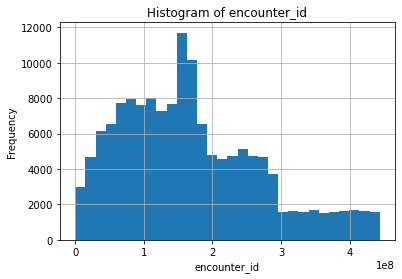

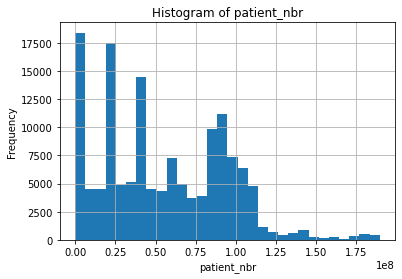

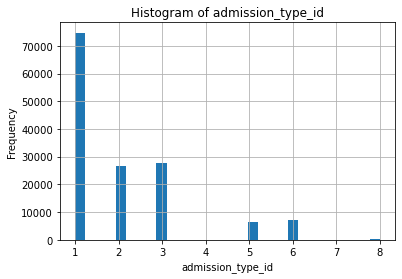

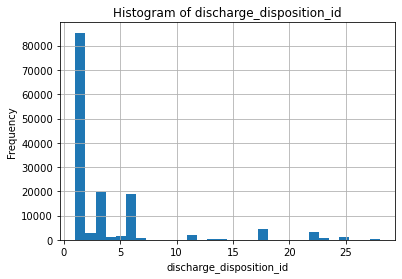

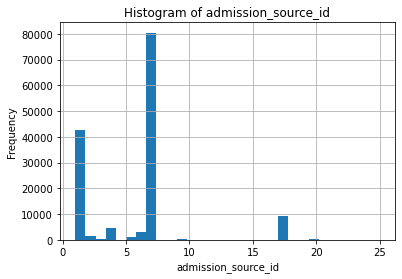

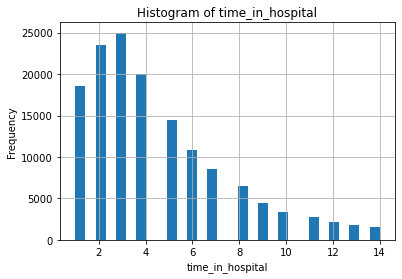

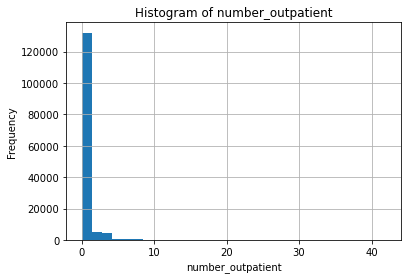

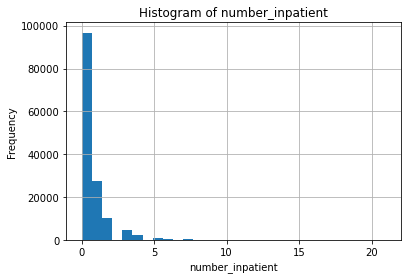

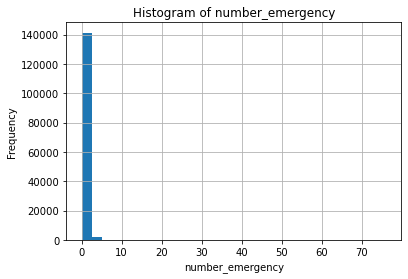

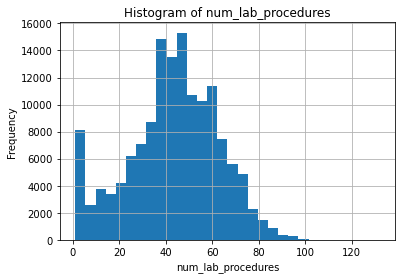

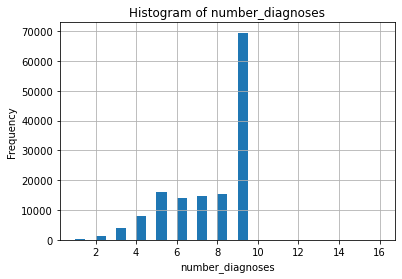

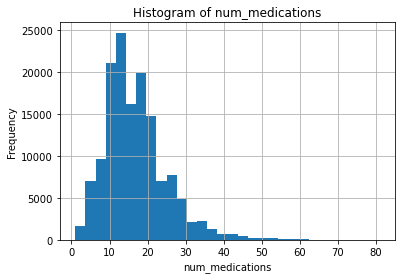

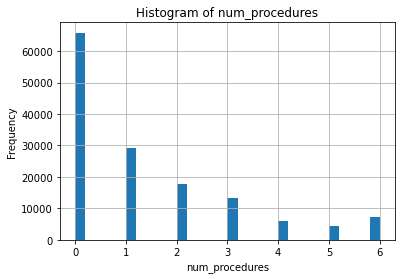

Numerical fields with Gaussian distribution shape:
 ['num_lab_procedures']


In [7]:
# Histogram Analysis
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('./data/final_project_dataset.csv')
numerical_data = data.select_dtypes(include=['float64', 'int64'])
# Plot histograms for each numerical field
for column in numerical_data.columns:
    plt.figure()
    numerical_data[column].hist(bins=30)
    plt.title(f'Histogram of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

# This conclusion is based on the plotted histogram shapes, not a formal
# normality test, which can reject visually reasonable shapes in large data.
gaussian_columns = ['num_lab_procedures']
print("Numerical fields with Gaussian distribution shape:\n", gaussian_columns)

- c) I focus high-cardinality analysis on categorical features rather than mixing categorical codes with identifiers and numeric measurements. The diagnosis-code fields have many categories because patients can have many distinct diagnoses and combinations of secondary diagnoses. `ndc_code` has many categories because it represents distinct drug products. I use 100 distinct categories as a screening threshold:

In [8]:
import pandas as pd

data = pd.read_csv('./data/final_project_dataset.csv')
categorical_columns = data.select_dtypes(include=['object', 'category']).columns
high_cardinality_columns = [
    col for col in categorical_columns if data[col].nunique() > 100
]
print("Fields with high cardinality:\n", high_cardinality_columns)

print("Number of unique values for each high cardinality field:\n", {col: data[col].nunique() for col in high_cardinality_columns})


Fields with high cardinality:
 ['primary_diagnosis_code', 'other_diagnosis_codes', 'ndc_code']
Number of unique values for each high cardinality field:
 {'primary_diagnosis_code': 717, 'other_diagnosis_codes': 19374, 'ndc_code': 251}


- d) Demographic distributions by age and gender:


Age distribution:
 [70-80)     36928
[60-70)     32741
[50-60)     25095
[80-90)     23527
[40-50)     13729
[30-40)      4964
[90-100)     3619
[20-30)      1927
[10-20)       733
[0-10)        161
Name: age, dtype: int64


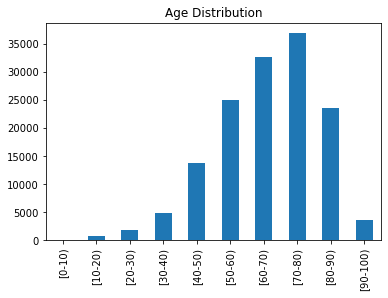


Gender distribution:
 Female             76185
Male               67234
Unknown/Invalid        5
Name: gender, dtype: int64


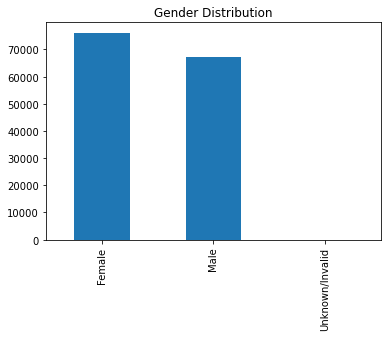

In [9]:
import pandas as pd

data = pd.read_csv('./data/final_project_dataset.csv')

print("Age distribution:\n", data['age'].value_counts())
# plot the age distribution
import matplotlib.pyplot as plt
data['age'].value_counts().sort_index().plot(kind='bar', title='Age Distribution')
plt.show()
print("\nGender distribution:\n", data['gender'].value_counts())
# plot the gender distribution
data['gender'].value_counts().plot(kind='bar', title='Gender Distribution')
plt.show()


As a conclusion, the dataset is skewed towards older patients: the [50-60), [60-70), [70-80), and [80-90) groups contain most observations, while patients under 40 are comparatively uncommon.

In [10]:
######NOTE: The visualization will only display in Chrome browser. ########
#import tensorflow_data_validation as tfdv
#full_data_stats = tfdv.generate_statistics_from_csv(data_location='./data/final_project_dataset.csv') 
#tfdv.visualize_statistics(full_data_stats)
#tf.data.TFRecordDataset(path='./data/final_project_dataset.tfrecord')

## Reduce Dimensionality of the NDC Code Feature

**Question 3**: NDC codes are a common format to represent the wide variety of drugs that are prescribed for patient care in the United States. The challenge is that there are many codes that map to the same or similar drug. You are provided with the ndc drug lookup file https://github.com/udacity/nd320-c1-emr-data-starter/blob/master/project/data_schema_references/ndc_lookup_table.csv derived from the National Drug Codes List site(https://ndclist.com/). Please use this file to come up with a way to reduce the dimensionality of this field and create a new field in the dataset called "generic_drug_name" in the output dataframe. 

**Response:**

Head of this file:

In [11]:
#NDC code lookup file
import pandas as pd
ndc_code_path = "./medication_lookup_tables/final_ndc_lookup_table"
ndc_code_df = pd.read_csv(ndc_code_path)
ndc_code_df.head()

,NDC_Code,Proprietary Name,Non-proprietary Name,Dosage Form,Route Name,Company Name,Product Type
0,0087-6060,Glucophage,Metformin Hydrochloride,"Tablet, Film Coated",Oral,Bristol-myers Squibb Company,Human Prescription Drug
1,0087-6063,Glucophage XR,Metformin Hydrochloride,"Tablet, Extended Release",Oral,Bristol-myers Squibb Company,Human Prescription Drug
2,0087-6064,Glucophage XR,Metformin Hydrochloride,"Tablet, Extended Release",Oral,Bristol-myers Squibb Company,Human Prescription Drug
3,0087-6070,Glucophage,Metformin Hydrochloride,"Tablet, Film Coated",Oral,Bristol-myers Squibb Company,Human Prescription Drug
4,0087-6071,Glucophage,Metformin Hydrochloride,"Tablet, Film Coated",Oral,Bristol-myers Squibb Company,Human Prescription Drug


I solve it by importing 'reduce_dimension_ndc' from 'student_utils', and this function returns a dataframe with joined generic drug name:

In [12]:
from student_utils import reduce_dimension_ndc

In [13]:
reduce_dim_df = reduce_dimension_ndc(df, ndc_code_df)
print(reduce_dim_df.columns)
print(
    reduce_dim_df[['ndc_code', 'generic_drug_name']]
    .drop_duplicates()
    .head(10)
)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'primary_diagnosis_code', 'other_diagnosis_codes', 'number_outpatient',
       'number_inpatient', 'number_emergency', 'num_lab_procedures',
       'number_diagnoses', 'num_medications', 'num_procedures', 'ndc_code',
       'max_glu_serum', 'A1Cresult', 'change', 'readmitted',
       'generic_drug_name'],
      dtype='object')
      ndc_code        generic_drug_name
0          NaN                      NaN
1   68071-1701            Human Insulin
2    0378-1110                Glipizide
4    0049-4110                Glipizide
6    47918-902            Insulin Human
7    35208-001  Metformin Hydrochloride
8    16729-001              Glimepiride
9    47918-891            Insulin Human
10   0115-1742                Glyburide
13   0173-0863    Rosiglitazone Maleate


In [14]:
print("Columnas en df:", 'ndc_code' in df.columns)
print("Columnas en reduce_dim_df:", 'generic_drug_name' in reduce_dim_df.columns)


Columnas en df: True
Columnas en reduce_dim_df: True


dimension of reduce_dim_df['generic_drug_name']:  22
dimension of df['ndc_code']:  251


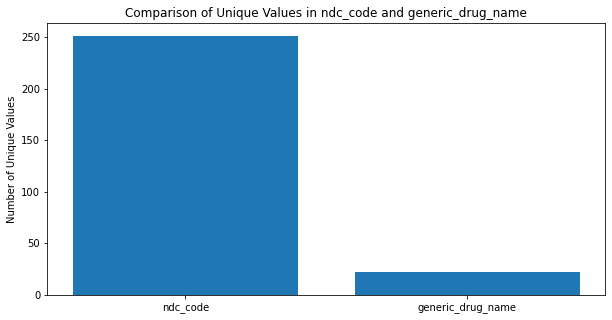

In [15]:
# Number of unique values should be less for the new output field
assert df['ndc_code'].nunique() > reduce_dim_df['generic_drug_name'].nunique()
print("dimension of reduce_dim_df['generic_drug_name']: ", reduce_dim_df['generic_drug_name'].nunique())
print("dimension of df['ndc_code']: ", df['ndc_code'].nunique())
# plot 
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(['ndc_code', 'generic_drug_name'], [df['ndc_code'].nunique(), reduce_dim_df['generic_drug_name'].nunique()])
plt.ylabel('Number of Unique Values')
plt.title('Comparison of Unique Values in ndc_code and generic_drug_name')
plt.show()

## Select First Encounter for each Patient 

**Question 4**: In order to simplify the aggregation of data for the model, we will only select the first encounter for each patient in the dataset. This is to reduce the risk of data leakage of future patient encounters and to reduce complexity of the data transformation and modeling steps. We will assume that sorting in numerical order on the encounter_id provides the time horizon for determining which encounters come before and after another.

**Response:**

In [16]:
from student_utils import select_first_encounter
first_encounter_df = select_first_encounter(reduce_dim_df)

In [17]:
# unique patients in transformed dataset
unique_patients = first_encounter_df['patient_nbr'].nunique()
print("Number of unique patients:{}".format(unique_patients))

# unique encounters in transformed dataset
unique_encounters = first_encounter_df['encounter_id'].nunique()
print("Number of unique encounters:{}".format(unique_encounters))

original_unique_patient_number = reduce_dim_df['patient_nbr'].nunique()
# number of unique patients should be equal to the number of unique encounters and patients in the final dataset
assert original_unique_patient_number == unique_patients
assert original_unique_patient_number == unique_encounters
print("Tests passed!!")

Number of unique patients:71518
Number of unique encounters:71518
Tests passed!!


## Aggregate Dataset to Right Level for Modeling 

In order to provide a broad scope of the steps and to prevent students from getting stuck with data transformations, we have selected the aggregation columns and provided a function to build the dataset at the appropriate level. The 'aggregate_dataset" function that you can find in the 'utils.py' file can take the preceding dataframe with the 'generic_drug_name' field and transform the data appropriately for the project. 

To make it simpler for students, we are creating dummy columns for each unique generic drug name and adding those are input features to the model. There are other options for data representation but this is out of scope for the time constraints of the course.

In [18]:
exclusion_list = ['generic_drug_name', 'ndc_code']
grouping_field_list = [c for c in first_encounter_df.columns if c not in exclusion_list]
agg_drug_df, ndc_col_list = aggregate_dataset(first_encounter_df, grouping_field_list, 'generic_drug_name')

In [19]:
assert len(agg_drug_df) == agg_drug_df['patient_nbr'].nunique() == agg_drug_df['encounter_id'].nunique()

## Prepare Fields and Cast Dataset 

### Feature Selection

**Question 5**: After you have aggregated the dataset to the right level, we can do feature selection (we will include the ndc_col_list, dummy column features too). In the block below, please select the categorical and numerical features that you will use for the model, so that we can create a dataset subset. 

For the payer_code and weight fields, please provide whether you think we should include/exclude the field in our model and give a justification/rationale for this based off of the statistics of the data. Feel free to use visualizations or summary statistics to support your choice.

**My response:**

I excluded: 'weight'/'payer_code' (very high missing rates), 'encounter_id'/'patient_nbr' (identifiers, not features), 'ndc_code'/'other_diagnosis_codes' (represented instead via ndc_col_list dummy columns), 'readmitted' (a post-encounter outcome that would leak information about time_in_hospital).

In [20]:
missing_marker_counts = (data[['payer_code', 'weight']] == '?').sum()
missing_marker_percentages = (
    missing_marker_counts / len(data) * 100
).round(2)

print("Missing values represented by '?':")
print(missing_marker_counts)

print("\nMissing percentages:")
print(missing_marker_percentages)

Missing values represented by '?':
payer_code     54190
weight        139122
dtype: int64

Missing percentages:
payer_code    37.78
weight        97.00
dtype: float64


- weight is excluded because 97% of its values are missing, making it unsuitable as a reliable model feature. 

- payer_code is excluded because approximately 37.8% of its values are missing, which could substantially reduce usable information and introduce missingness-related bias.

In [ ]:
# I had to update the lists to include the required demographic features

required_demo_col_list = ['race', 'gender', 'age']
student_categorical_col_list = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id',
        'medical_specialty', 'primary_diagnosis_code', 'max_glu_serum', 'A1Cresult',
        'change'] + required_demo_col_list + ndc_col_list
student_numerical_col_list = ['number_outpatient', 'number_inpatient', 'number_emergency',
        'num_lab_procedures', 'number_diagnoses', 'num_medications', 'num_procedures']
PREDICTOR_FIELD = 'time_in_hospital'


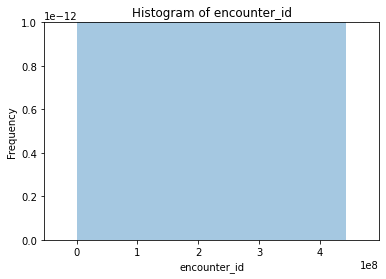

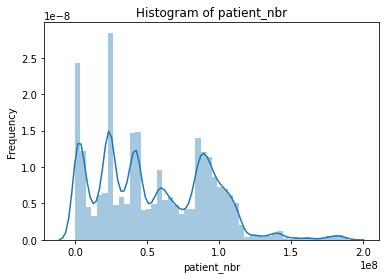

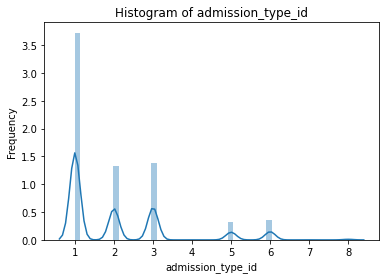

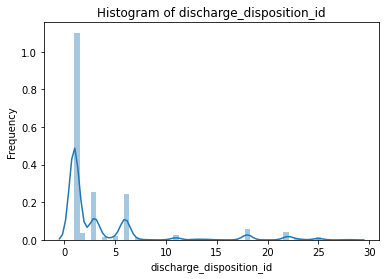

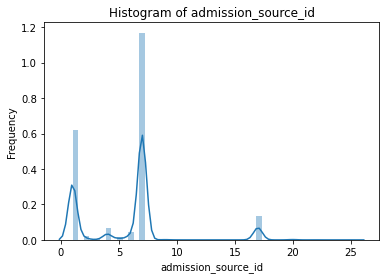

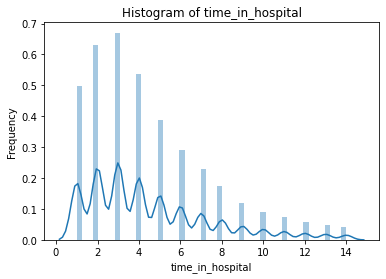

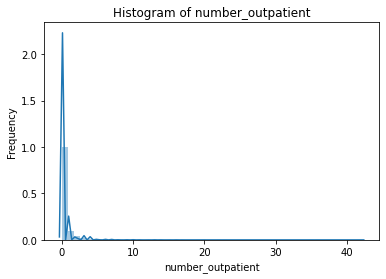

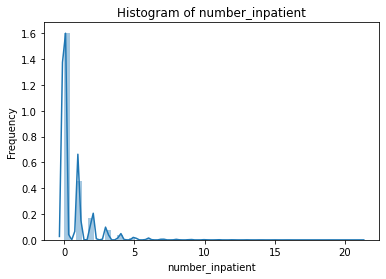

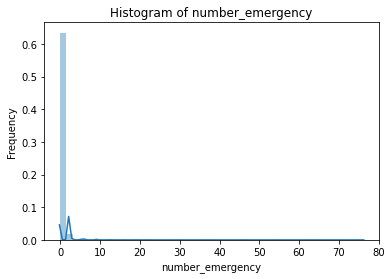

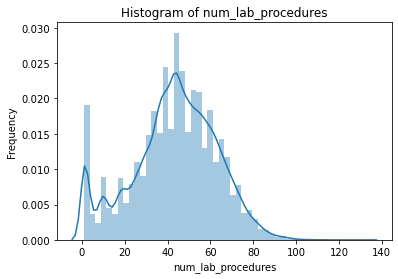

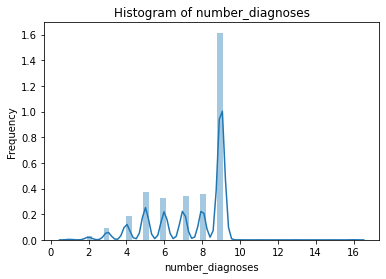

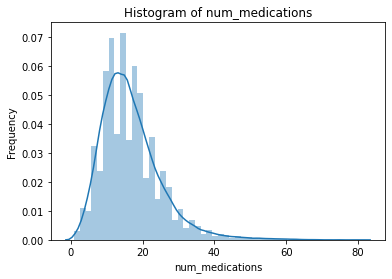

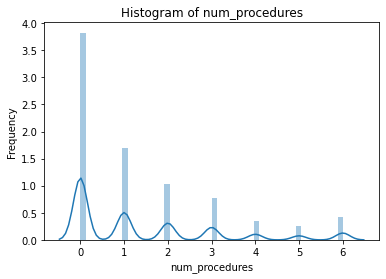

In [22]:
import seaborn as sns

for column in numerical_data.columns:
    plt.figure()
    sns.distplot(numerical_data[column].dropna(), kde=True) 
    plt.title(f'Histogram of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()


In [23]:
def select_model_features(df, categorical_col_list, numerical_col_list, PREDICTOR_FIELD, grouping_key='patient_nbr'):
    selected_col_list = [grouping_key] + [PREDICTOR_FIELD] + categorical_col_list + numerical_col_list   
    return agg_drug_df[selected_col_list]


In [24]:
selected_features_df = select_model_features(agg_drug_df, student_categorical_col_list, student_numerical_col_list,
                                            PREDICTOR_FIELD)

### Preprocess Dataset - Casting and Imputing  

We will cast and impute the dataset before splitting so that we do not have to repeat these steps across the splits in the next step. For imputing, there can be deeper analysis into which features to impute and how to impute but for the sake of time, we are taking a general strategy of imputing zero for only numerical features. 

OPTIONAL: What are some potential issues with this approach? Can you recommend a better way and also implement it?

Answer to OPTIONAL: The approach outlined introduces two major flaws into a machine learning workflow: data leakage (due to the timing of the split) and distorted feature distributions (due to the naive imputation strategy).

In [25]:
processed_df = preprocess_df(selected_features_df, student_categorical_col_list, 
        student_numerical_col_list, PREDICTOR_FIELD, categorical_impute_value='nan', numerical_impute_value=0)

/workspace/home/starter_code/utils.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[predictor] = df[predictor].astype(float)
/workspace/home/starter_code/utils.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[c] = cast_df(df, c, d_type=str)
/workspace/home/starter_code/utils.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pa

## Split Dataset into Train, Validation, and Test Partitions

**Question 6**: In order to prepare the data for being trained and evaluated by a deep learning model, we will split the dataset into three partitions, with the validation partition used for optimizing the model hyperparameters during training. One of the key parts is that we need to be sure that the data does not accidently leak across partitions.

Please complete the function below to split the input dataset into three partitions(train, validation, test) with the following requirements.
- Approximately 60%/20%/20%  train/validation/test split
- Randomly sample different patients into each data partition
- **IMPORTANT** Make sure that a patient's data is not in more than one partition, so that we can avoid possible data leakage.
- Make sure that the total number of unique patients across the splits is equal to the total number of unique patients in the original dataset
- Total number of rows in original dataset = sum of rows across all three dataset partitions

In [ ]:
from student_utils import patient_dataset_splitter
# ANSWER: I completed the function in student_utils.py
d_train, d_val, d_test = patient_dataset_splitter(processed_df, 'patient_nbr')

In [27]:
assert len(d_train) + len(d_val) + len(d_test) == len(processed_df)
print("Test passed for number of total rows equal!")

Test passed for number of total rows equal!


In [28]:
assert (d_train['patient_nbr'].nunique() + d_val['patient_nbr'].nunique() + d_test['patient_nbr'].nunique()) == agg_drug_df['patient_nbr'].nunique()
print("Test passed for number of unique patients being equal!")

Test passed for number of unique patients being equal!


## Demographic Representation Analysis of Split

After the split, we should check to see the distribution of key features/groups and make sure that there is representative samples across the partitions. The show_group_stats_viz function in the utils.py file can be used to group and visualize different groups and dataframe partitions.

### Label Distribution Across Partitions

Below you can see the distributution of the label across your splits. Are the histogram distribution shapes similar across partitions?

time_in_hospital
1.0     10717
2.0     12397
3.0     12701
4.0      9567
5.0      6839
6.0      5171
7.0      3999
8.0      2919
9.0      1990
10.0     1558
11.0     1241
12.0      955
13.0      795
14.0      669
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


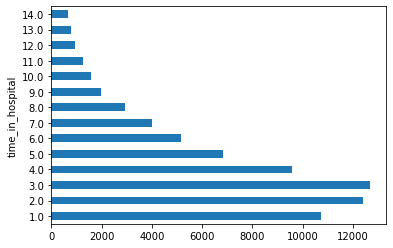

In [29]:
show_group_stats_viz(processed_df, PREDICTOR_FIELD)

time_in_hospital
1.0     6395
2.0     7461
3.0     7750
4.0     5743
5.0     4051
6.0     3109
7.0     2364
8.0     1744
9.0     1173
10.0     919
11.0     739
12.0     549
13.0     489
14.0     424
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


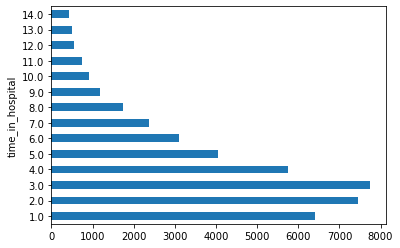

In [30]:
show_group_stats_viz(d_train, PREDICTOR_FIELD)

time_in_hospital
1.0     2119
2.0     2436
3.0     2506
4.0     1949
5.0     1399
6.0     1022
7.0      803
8.0      600
9.0      410
10.0     323
11.0     249
12.0     205
13.0     164
14.0     120
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


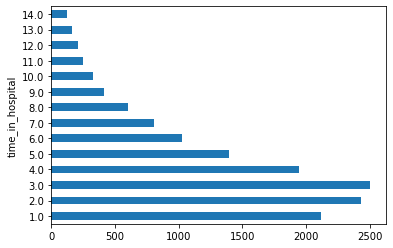

In [31]:
show_group_stats_viz(d_test, PREDICTOR_FIELD)

Answer: Yes, if we look at the axis, we can see they have similar profiles.

## Demographic Group Analysis

We should check that our partitions/splits of the dataset are similar in terms of their demographic profiles. Below you can see how we might visualize and analyze the full dataset vs. the partitions.

gender
Female             38025
Male               33490
Unknown/Invalid        3
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


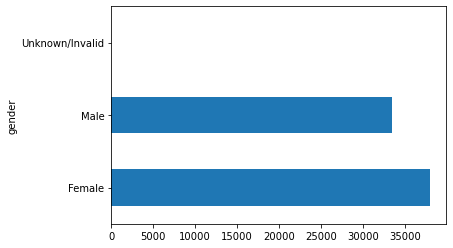

In [32]:
# Full dataset before splitting
patient_demo_features = ['race', 'gender', 'age', 'patient_nbr']
patient_group_analysis_df = processed_df[patient_demo_features].groupby('patient_nbr').head(1).reset_index(drop=True)
show_group_stats_viz(patient_group_analysis_df, 'gender')

gender
Female             22815
Male               20094
Unknown/Invalid        1
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


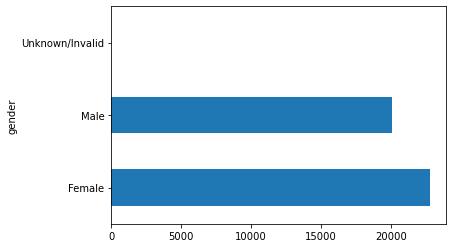

In [33]:
# Training partition
show_group_stats_viz(d_train, 'gender')

gender
Female             7557
Male               6747
Unknown/Invalid       1
dtype: int64
AxesSubplot(0.125,0.125;0.775x0.755)


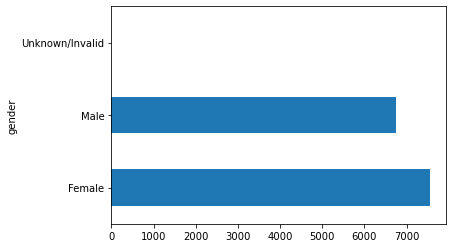

In [34]:
# Test partition
show_group_stats_viz(d_test, 'gender')

## Convert Dataset Splits to TF Dataset

We have provided you the function to convert the Pandas dataframe to TF tensors using the TF Dataset API. 
Please note that this is not a scalable method and for larger datasets, the 'make_csv_dataset' method is recommended -https://www.tensorflow.org/api_docs/python/tf/data/experimental/make_csv_dataset.

In [35]:
# Convert dataset from Pandas dataframes to TF dataset 
batch_size = 128
diabetes_train_ds = df_to_dataset(d_train, PREDICTOR_FIELD, batch_size=batch_size)
diabetes_val_ds = df_to_dataset(d_val, PREDICTOR_FIELD, batch_size=batch_size)
diabetes_test_ds = df_to_dataset(d_test, PREDICTOR_FIELD, batch_size=batch_size)

In [36]:
# We use this sample of the dataset to show transformations later
diabetes_batch = next(iter(diabetes_train_ds))[0]
def demo(feature_column, example_batch):
    feature_layer = layers.DenseFeatures(feature_column)
    print(feature_layer(example_batch))

# 4. Create Categorical Features with TF Feature Columns

## Build Vocabulary for Categorical Features

Before we can create the TF categorical features, we must first create the vocab files with the unique values for a given field that are from the **training** dataset. Below we have provided a function that you can use that only requires providing the pandas train dataset partition and the list of the categorical columns in a list format. The output variable 'vocab_file_list' will be a list of the file paths that can be used in the next step for creating the categorical features.

In [37]:
vocab_file_list = build_vocab_files(d_train, student_categorical_col_list)

## Create Categorical Features with Tensorflow Feature Column API

**Question 7**: Using the vocab file list from above that was derived fromt the features you selected earlier, please create categorical features with the Tensorflow Feature Column API, https://www.tensorflow.org/api_docs/python/tf/feature_column. Below is a function to help guide you.

In [ ]:
from student_utils import create_tf_categorical_feature_cols 
# I completed this function in student_utils.py
tf_cat_col_list = create_tf_categorical_feature_cols(student_categorical_col_list)

INFO:tensorflow:vocabulary_size = 9 in admission_type_id is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/admission_type_id_vocab.txt.
INFO:tensorflow:vocabulary_size = 27 in discharge_disposition_id is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/discharge_disposition_id_vocab.txt.
INFO:tensorflow:vocabulary_size = 17 in admission_source_id is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/admission_source_id_vocab.txt.
INFO:tensorflow:vocabulary_size = 66 in medical_specialty is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/medical_specialty_vocab.txt.
INFO:tensorflow:vocabulary_size = 648 in primary_diagnosis_code is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/primary_diagnosis_code_vocab.txt.
INFO:tensorflow:vocabulary_size = 5 in max_glu_serum is inferred from the number of elements in the vocabulary_file ./diabetes_vocab/max_

In [39]:
from utils import build_vocab_files, show_group_stats_viz, aggregate_dataset, preprocess_df, df_to_dataset, posterior_mean_field, prior_trainable

test_cat_var1 = tf_cat_col_list[0]
print("Example categorical field:\n{}".format(test_cat_var1))
demo(test_cat_var1, diabetes_batch)

Example categorical field:
IndicatorColumn(categorical_column=VocabularyFileCategoricalColumn(key='admission_type_id', vocabulary_file='./diabetes_vocab/admission_type_id_vocab.txt', vocabulary_size=9, num_oov_buckets=1, dtype=tf.string, default_value=-1))
Instructions for updating:
The old _FeatureColumn APIs are being deprecated. Please use the new FeatureColumn APIs instead.
Instructions for updating:
The old _FeatureColumn APIs are being deprecated. Please use the new FeatureColumn APIs instead.
tf.Tensor(
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]], shape=(128, 10), dtype=float32)


# 5. Create Numerical Features with TF Feature Columns

**Question 8**: Using the TF Feature Column API(https://www.tensorflow.org/api_docs/python/tf/feature_column/), please create normalized Tensorflow numeric features for the model. Try to use the z-score normalizer function below to help as well as the 'calculate_stats_from_train_data' function.

In [ ]:
from student_utils import create_tf_numeric_feature
# I completed this function in student_utils.py

For simplicity the create_tf_numerical_feature_cols function below uses the same normalizer function across all features(z-score normalization) but if you have time feel free to analyze and adapt the normalizer based off the statistical distributions. You may find this as a good resource in determining which transformation fits best for the data https://developers.google.com/machine-learning/data-prep/transform/normalization.


In [41]:
def calculate_stats_from_train_data(df, col):
    mean = df[col].describe()['mean']
    std = df[col].describe()['std']
    return mean, std

def create_tf_numerical_feature_cols(numerical_col_list, train_df):
    tf_numeric_col_list = []
    for c in numerical_col_list:
        mean, std = calculate_stats_from_train_data(train_df, c)
        tf_numeric_feature = create_tf_numeric_feature(c, mean, std)
        tf_numeric_col_list.append(tf_numeric_feature)
    return tf_numeric_col_list

In [42]:
tf_cont_col_list = create_tf_numerical_feature_cols(student_numerical_col_list, d_train)

In [43]:
test_cont_var1 = tf_cont_col_list[0]
print("Example continuous field:\n{}\n".format(test_cont_var1))
demo(test_cont_var1, diabetes_batch)

Example continuous field:
NumericColumn(key='number_outpatient', shape=(1,), default_value=(0,), dtype=tf.float32, normalizer_fn=<function create_tf_numeric_feature.<locals>.z_score_normalizer at 0x7e55a3260ef0>)

tf.Tensor(
[[-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [ 1.639833  ]
 [-0.26566383]
 [-0.26566383]
 [ 1.639833  ]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [ 0.68708456]
 [-0.26566383]
 [ 0.68708456]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [ 5.4508266 ]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566383]
 [-0.26566

# 6. Build Deep Learning Regression Model with Sequential API and TF Probability Layers

## Use DenseFeatures to combine features for model

Now that we have prepared categorical and numerical features using Tensorflow's Feature Column API, we can combine them into a dense vector representation for the model. Below we will create this new input layer, which we will call 'claim_feature_layer'.

In [44]:
claim_feature_columns = tf_cat_col_list + tf_cont_col_list
claim_feature_layer = tf.keras.layers.DenseFeatures(claim_feature_columns)

## Build Sequential API Model from DenseFeatures and TF Probability Layers

Below we have provided some boilerplate code for building a model that connects the Sequential API, DenseFeatures, and Tensorflow Probability layers into a deep learning model. There are many opportunities to further optimize and explore different architectures through benchmarking and testing approaches in various research papers, loss and evaluation metrics, learning curves, hyperparameter tuning, TF probability layers, etc. Feel free to modify and explore as you wish.

**OPTIONAL**: Come up with a more optimal neural network architecture and hyperparameters. Share the process in discovering the architecture and hyperparameters.

In [45]:
def build_sequential_model(feature_layer):
    model = tf.keras.Sequential([
        feature_layer,
        tf.keras.layers.Dense(150, activation='relu'),
        tf.keras.layers.Dense(75, activation='relu'),
        tfp.layers.DenseVariational(1+1, posterior_mean_field, prior_trainable),
        tfp.layers.DistributionLambda(
            lambda t:tfp.distributions.Normal(loc=t[..., :1],
                                             scale=1e-3 + tf.math.softplus(0.01 * t[...,1:])
                                             )
        ),
    ])
    return model

def build_diabetes_model(train_ds, val_ds,  feature_layer,  epochs=5, loss_metric='mse'):
    model = build_sequential_model(feature_layer)
    model.compile(optimizer='rmsprop', loss=loss_metric, metrics=[loss_metric])
    early_stop = tf.keras.callbacks.EarlyStopping(monitor=loss_metric, patience=3)     
    history = model.fit(train_ds, validation_data=val_ds,
                        callbacks=[early_stop],
                        epochs=epochs)
    return model, history 

In [46]:
diabetes_model, history = build_diabetes_model(diabetes_train_ds, diabetes_val_ds,  claim_feature_layer,  epochs=10)

Train for 336 steps, validate for 112 steps
Epoch 1/10
336/336 [==============================] - 18s 54ms/step - loss: 24.7595 - mse: 24.5842 - val_loss: 21.4630 - val_mse: 21.0749
Epoch 2/10
336/336 [==============================] - 14s 41ms/step - loss: 16.9204 - mse: 16.2696 - val_loss: 13.6543 - val_mse: 12.8097
Epoch 3/10
336/336 [==============================] - 14s 43ms/step - loss: 12.4066 - mse: 11.5671 - val_loss: 12.9625 - val_mse: 12.2549
Epoch 4/10
336/336 [==============================] - 14s 41ms/step - loss: 11.5154 - mse: 10.6510 - val_loss: 10.7076 - val_mse: 9.7073
Epoch 5/10
336/336 [==============================] - 14s 40ms/step - loss: 10.3633 - mse: 9.5073 - val_loss: 9.3677 - val_mse: 8.4860
Epoch 6/10
336/336 [==============================] - 14s 41ms/step - loss: 9.7230 - mse: 8.8539 - val_loss: 9.4087 - val_mse: 8.6814
Epoch 7/10
336/336 [==============================] - 13s 40ms/step - loss: 9.3017 - mse: 8.3974 - val_loss: 8.9139 - val_mse: 8.0781
Ep

## Show Model Uncertainty Range with TF Probability

**Question 9**: Now that we have trained a model with TF Probability layers, we can extract the mean and standard deviation for each prediction. Please fill in the answer for the m and s variables below. The code for getting the predictions is provided for you below.

In [47]:
feature_list = student_categorical_col_list + student_numerical_col_list
diabetes_x_tst = dict(d_test[feature_list])
diabetes_yhat = diabetes_model(diabetes_x_tst)
preds = diabetes_model.predict(diabetes_test_ds)

In [ ]:
from student_utils import get_mean_std_from_preds
# I completed this function in student_utils.py
m, s = get_mean_std_from_preds(diabetes_yhat)

In [49]:
print(diabetes_yhat)


tfp.distributions.Normal("sequential/distribution_lambda/Normal/", batch_shape=[14305, 1], event_shape=[], dtype=float32)


## Show Prediction Output 

In [50]:
prob_outputs = {
    "pred": preds.flatten(),
    "actual_value": d_test['time_in_hospital'].values,
    "pred_mean": m.numpy().flatten(),
    "pred_std": s.numpy().flatten()
}
prob_output_df = pd.DataFrame(prob_outputs)

In [51]:
prob_output_df.head()

,pred,actual_value,pred_mean,pred_std
0,1.547301,7.0,4.000813,0.683884
1,0.834505,5.0,3.348351,0.689300
2,0.352316,4.0,3.042515,0.690601
3,3.713327,2.0,3.152460,0.691450
4,1.285178,11.0,7.114974,0.678903


## Convert Regression Output to Classification Output for Patient Selection

**Question 10**: Given the output predictions, convert it to a binary label for whether the patient meets the time criteria or does not (HINT: use the mean prediction numpy array). The expected output is a numpy array with a 1 or 0 based off if the prediction meets or doesnt meet the criteria.

In [ ]:
from student_utils import get_student_binary_prediction
# I completed this function in student_utils.py
student_binary_prediction = get_student_binary_prediction(prob_output_df, 'pred_mean')

### Add Binary Prediction to Test Dataframe

Using the student_binary_prediction output that is a numpy array with binary labels, we can use this to add to a dataframe to better visualize and also to prepare the data for the Aequitas toolkit. The Aequitas toolkit requires that the predictions be mapped to a binary label for the predictions (called 'score' field) and the actual value (called 'label_value').

In [53]:
def add_pred_to_test(test_df, pred_np, demo_col_list):
    for c in demo_col_list:
        test_df[c] = test_df[c].astype(str)
    test_df['score'] = pred_np
    test_df['label_value'] = test_df['time_in_hospital'].apply(lambda x: 1 if x >=5 else 0)
    return test_df

pred_test_df = add_pred_to_test(d_test, student_binary_prediction, ['race', 'gender'])

In [54]:
pred_test_df[['patient_nbr', 'gender', 'race', 'time_in_hospital', 'score', 'label_value']].head()

,patient_nbr,gender,race,time_in_hospital,score,label_value
0,77391171,Male,AfricanAmerican,7.0,0,1
1,114882984,Male,Caucasian,5.0,0,1
2,92519352,Male,AfricanAmerican,4.0,0,0
3,63000108,Female,AfricanAmerican,2.0,0,0
4,107400762,Female,Caucasian,11.0,1,1


## Model Evaluation Metrics 

**Question 11**: Now it is time to use the newly created binary labels in the 'pred_test_df' dataframe to evaluate the model with some common classification metrics. Please create a report summary of the performance of the model and be sure to give the ROC AUC, F1 score(weighted), class precision and recall scores. 

For the report please be sure to include the following three parts:
- With a non-technical audience in mind, explain the precision-recall tradeoff in regard to how you have optimized your model.

- What are some areas of improvement for future iterations?

**Response:**

In [55]:
# AUC, F1, precision and recall
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, classification_report

y_true = pred_test_df['label_value'].values
y_pred = pred_test_df['score'].values
y_mean = prob_output_df['pred_mean'].values

print("AUC, F1, precision and recall")
print("ROC AUC (predicted mean vs label):", roc_auc_score(y_true, y_mean))
print("ROC AUC (binary prediction):", roc_auc_score(y_true, y_pred))
print("F1 (weighted):", f1_score(y_true, y_pred, average='weighted'))
print("Precision (weighted):", precision_score(y_true, y_pred, average='weighted'))
print("Recall (weighted):", recall_score(y_true, y_pred, average='weighted'))
print(classification_report(y_true, y_pred, target_names=['stay < 5 days', 'stay >= 5 days']))


AUC, F1, precision and recall
ROC AUC (predicted mean vs label): 0.8504166181946614
ROC AUC (binary prediction): 0.6690143361850593
F1 (weighted): 0.7138300005937598
Precision (weighted): 0.7791769926114324
Recall (weighted): 0.7468717231737155
                precision    recall  f1-score   support

 stay < 5 days       0.72      0.97      0.83      9010
stay >= 5 days       0.87      0.37      0.52      5295

      accuracy                           0.75     14305
     macro avg       0.80      0.67      0.67     14305
  weighted avg       0.78      0.75      0.71     14305



The model has high precision for predicting stays of at least five days (0.87), meaning that patients predicted to have longer stays are usually correctly identified. However, recall for this group is low (0.37), so the model misses many patients who actually have stays of at least five days. If identifying all potentially eligible longer-stay patients is important, we could lower the classification threshold below five predicted days to improve recall, accepting more false positives and lower precision.

The training and validation losses both decreased over the training epochs, without a clear validation-loss increase, so there is no strong evidence of severe overfitting in this run. Future work should compare training and validation learning curves across more epochs and model sizes, use early stopping based on validation loss, and tune regularization or network complexity. A model that is too simple may underfit and miss real relationships; one that is too complex may overfit and perform poorly on unseen patients.

# 7. Evaluating Potential Model Biases with Aequitas Toolkit

## Prepare Data For Aequitas Bias Toolkit 

Using the gender and race fields, we will prepare the data for the Aequitas Toolkit.

In [56]:
# Aequitas
from aequitas.preprocessing import preprocess_input_df
from aequitas.group import Group
from aequitas.plotting import Plot
from aequitas.bias import Bias
from aequitas.fairness import Fairness

ae_subset_df = pred_test_df[['race', 'gender', 'score', 'label_value']]
ae_df, _ = preprocess_input_df(ae_subset_df)
g = Group()
xtab, _ = g.get_crosstabs(ae_df)
absolute_metrics = g.list_absolute_metrics(xtab)
clean_xtab = xtab.copy()
aqp = Plot()
b = Bias()


model_id, score_thresholds 1 {'rank_abs': [2236]}


/opt/conda/lib/python3.7/site-packages/aequitas/group.py:143: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['score'] = df['score'].astype(float)
/opt/conda/lib/python3.7/site-packages/aequitas/group.py:30: FutureWarning: The pandas.np module is deprecated and will be removed from pandas in a future version. Import numpy directly instead
  divide = lambda x, y: x / y if y != 0 else pd.np.nan


## Reference Group Selection

Below we have chosen the reference group for our analysis but feel free to select another one.

In [57]:
# test reference group with Caucasian Male
bdf = b.get_disparity_predefined_groups(clean_xtab, 
                    original_df=ae_df, 
                    ref_groups_dict={'race':'Caucasian', 'gender':'Male'
                                     }, 
                    alpha=0.05, 
                    check_significance=False)


f = Fairness()
fdf = f.get_group_value_fairness(bdf)

get_disparity_predefined_group()


/opt/conda/lib/python3.7/site-packages/aequitas/bias.py:368: FutureWarning: The pandas.np module is deprecated and will be removed from pandas in a future version. Import numpy directly instead
  df = df.replace(pd.np.inf, fill_divbyzero)
/opt/conda/lib/python3.7/site-packages/aequitas/fairness.py:32: FutureWarning: The pandas.np module is deprecated and will be removed from pandas in a future version. Import numpy directly instead
  self.fair_eval = lambda tau: lambda x: pd.np.nan if pd.np.isnan(x) else \
/opt/conda/lib/python3.7/site-packages/aequitas/fairness.py:45: FutureWarning: The pandas.np module is deprecated and will be removed from pandas in a future version. Import numpy directly instead
  self.high_level_pair_eval = lambda col1, col2: lambda x: pd.np.nan if (pd.np.isnan(x[col1]) and pd.np.isnan(x[col2])) \


## Race and Gender Bias Analysis for Patient Selection

**Question 12**: For the gender and race fields, please plot two metrics that are important for patient selection below and state whether there is a significant bias in your model across any of the groups along with justification for your statement.

**Response:**

get_disparity_predefined_group()


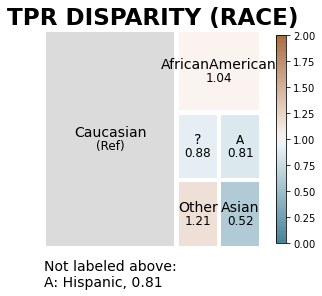

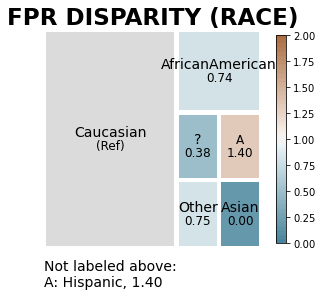

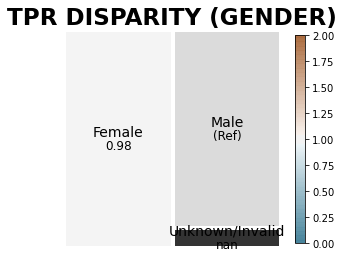

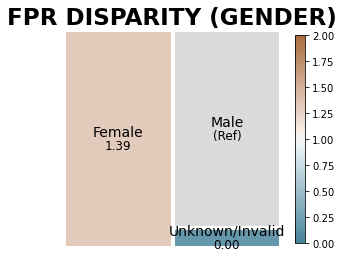

In [58]:
# Plot two metrics that are important for patient selection
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

bdf = b.get_disparity_predefined_groups(clean_xtab,
                    original_df=ae_df,
                    ref_groups_dict={'race':'Caucasian', 'gender':'Male'},
                    alpha=0.05,
                    check_significance=False)

f = Fairness()
fdf = f.get_group_value_fairness(bdf)

aqp.plot_disparity(bdf, group_metric='tpr_disparity', attribute_name='race')
aqp.plot_disparity(bdf, group_metric='fpr_disparity', attribute_name='race')
aqp.plot_disparity(bdf, group_metric='tpr_disparity', attribute_name='gender')
aqp.plot_disparity(bdf, group_metric='fpr_disparity', attribute_name='gender')
# Is there significant bias in your model for either race or gender?

Relative to the Male reference group, the Female group has an FPR disparity of 1.17 and fails FPR parity. This means that female patients are predicted as having a stay of at least five days at a substantially higher false-positive rate than male patients.

Relative to the Caucasian reference group, the Hispanic group has a TPR disparity of 0.92 and FPR disparity of 1.54, fails to both parity checks. These results indicate that model error rates are not consistent across demographic groups, so the model should be investigated before use in patient-selection decisions.

## Fairness Analysis Example - Relative to a Reference Group 

**Question 13**: Earlier we defined our reference group and then calculated disparity metrics relative to this grouping. Please provide a visualization of the fairness evaluation for this reference group and analyze whether there is disparity.

**Response:**

Reference-group fairness plot (reference groups: Caucasian and Male)
attribute_name  attribute_value    tpr  tpr_disparity TPR Parity
          race                ?  0.324          0.878       True
          race  AfricanAmerican  0.384          1.041       True
          race            Asian  0.192          0.522      False
          race        Caucasian  0.369          1.000       True
          race         Hispanic  0.298          0.808       True
          race            Other  0.446          1.210       True
        gender           Female  0.365          0.977       True
        gender             Male  0.374          1.000       True


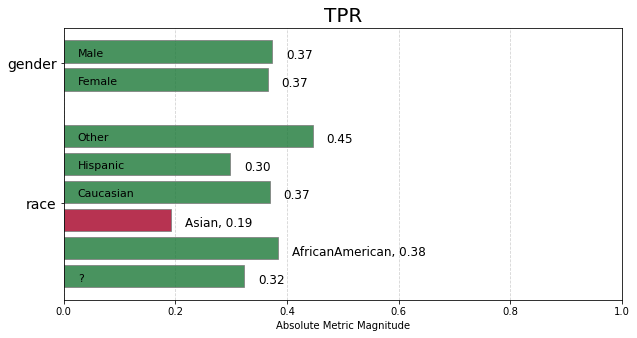

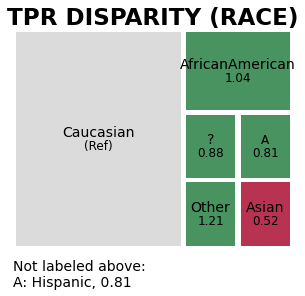

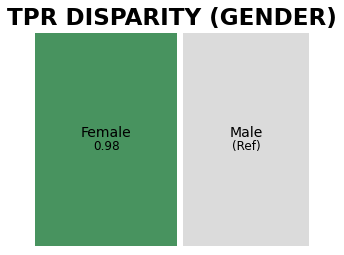

In [59]:
# Reference group fairness plot (reference group: Caucasian, Male), using the Aequitas objects built above
import numpy as np

valid_tpr_fdf = (
    fdf.replace([np.inf, -np.inf], np.nan)
       .dropna(subset=['tpr', 'tpr_disparity'])
       .copy()
)

print("Reference-group fairness plot (reference groups: Caucasian and Male)")

if valid_tpr_fdf.empty:
    print("No groups have defined TPR and TPR disparity values to plot.")
else:
    aqp.plot_fairness_group(valid_tpr_fdf, group_metric='tpr', title=True)
    aqp.plot_fairness_disparity(
        valid_tpr_fdf,
        group_metric='tpr',
        attribute_name='race'
    )
    aqp.plot_fairness_disparity(
        valid_tpr_fdf,
        group_metric='tpr',
        attribute_name='gender'
    )

    print(
        valid_tpr_fdf[
            ['attribute_name', 'attribute_value', 'tpr', 'tpr_disparity',
             'TPR Parity']
        ].round(3).to_string(index=False)
    )

if fdf['fpr_disparity'].isna().any():
    print(
        "\nFPR disparity is undefined because the reference group's FPR is "
        "zero; therefore, it is not plotted as a ratio."
    )

Disparity analysis involved examining differences in model performance or outcomes across different demographic groups. It helps to identify potential biases and ensures that the model treats all groups fairly. In this case we would confirm disparity of Gender.